In [1]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile
import os

# --- 1. Define Paths ---
# IMPORTANT: Replace these with your actual file name and desired extraction folder
ZIP_FILE_PATH = '/content/drive/MyDrive/archive.zip'
DESTINATION_FOLDER = '/content/drive/MyDrive/MyData/Extracted_Dataset'

# --- 2. Create Destination Folder (If it doesn't exist) ---
# The exist_ok=True argument prevents an error if the folder already exists.
os.makedirs(DESTINATION_FOLDER, exist_ok=True)ng extraction: {e}")

Starting extraction of: /content/drive/MyDrive/archive.zip
✅ Extraction complete! Files saved to: /content/drive/MyDrive/MyData/Extracted_Dataset


In [ ]:
import zipfile
import os

# --- 1. Define Paths ---
# IMPORTANT: Replace these with your actual file name and desired extraction folder
ZIP_FILE_PATH = '/content/drive/MyDrive/archive.zip'
DESTINATION_FOLDER = '/content/drive/MyDrive/MyData/Extracted_Dataset'

# --- 2. Create Destination Folder (If it doesn't exist) ---
# The exist_ok=True argument prevents an error if the folder already exists.
os.makedirs(DESTINATION_FOLDER, exist_ok=True)

# --- 3. Extract the Zip File ---
print(f"Starting extraction of: {ZIP_FILE_PATH}")

try:
    with zipfile.ZipFile(ZIP_FILE_PATH, 'r') as zip_ref:
        # Extract all contents into the specified destination folder
        zip_ref.extractall(DESTINATION_FOLDER)

    print(f"✅ Extraction complete! Files saved to: {DESTINATION_FOLDER}")

except FileNotFoundError:
    print(f"❌ Error: The file was not found at {ZIP_FILE_PATH}. Check your path!")
except Exception as e:
    print(f"❌ An error occurred during extraction: {e}")

Starting extraction of: /content/drive/MyDrive/archive.zip
✅ Extraction complete! Files saved to: /content/drive/MyDrive/MyData/Extracted_Dataset


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

base_dir = "/content/drive/MyDrive/MyData/Extracted_dataset"  # <-- change to your actual path
for folder in os.listdir(base_dir):
    print(folder)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/MyData/Extracted_dataset'

In [ ]:
!ls /content

drive  sample_data


In [ ]:
!ls /content/drive/MyDrive

 1.c
 1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf
 20241207_090732.jpg
 20241207_090737.jpg
 20241207_090740.jpg
 20241207_115024.jpg
 20241207_115038.jpg
 20241210_091021.jpg
'4SN23CS099 (1).jpg'
 4SN23CS099.jpg
 4SN23CS099_Sapna.docx
'Activity_LifeStyle[1] (1).docx'
'Activity_LifeStyle[1].docx'
'AI notes'
'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf'
 archive.zip
 ARM-contrlr-Module-1.pdf
 Classroom
'Colab Notebooks'
'Document from Sapna Shetty (1).pdf'
'Document from Sapna Shetty (2).pdf'
'Document from Sapna Shetty.pdf'
 Ieee
 InShot_20250325_125240493.jpg
'Mehendi and Pooje'
'Milling operation.pdf'
 MyData
 pooje
 Screenshot_20241105-225830_PhonePe.jpg
 Screenshot_20241202-164326_Messages.jpg
'Share Client_security_hash (1).pdf'
'Students Registration.gsheet'
'Untitled form (1).gform'
'Untitled form.gform'
'VTU Result 2024.PDF.pdf'


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/archive.zip"   # your actual zip file path
extract_to = "/content/drive/MyDrive/Extracted_dataset"         # where we’ll unzip it

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

print("✅ Extraction complete! Files are in:", extract_to)

✅ Extraction complete! Files are in: /content/drive/MyDrive/Extracted_dataset


In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset

melanoma_cancer_dataset


In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset

test  train


In [ ]:
train_dir = "/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/train"
test_dir = "/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/test"

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

Found 9605 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

cnn_model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')  # binary output: benign(0) / malignant(1)
])

cnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = cnn_model.fit(train_gen, epochs=10, validation_data=test_gen)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 1178s 4s/step - accuracy: 0.7274 - loss: 0.6177 - val_accuracy: 0.8730 - val_loss: 0.2792
Epoch 2/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 1157s 4s/step - accuracy: 0.8674 - loss: 0.3155 - val_accuracy: 0.8840 - val_loss: 0.2642
Epoch 3/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 1135s 4s/step - accuracy: 0.8720 - loss: 0.3062 - val_accuracy: 0.8970 - val_loss: 0.2425
Epoch 4/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 1143s 4s/step - accuracy: 0.8761 - loss: 0.3044 - val_accuracy: 0.8920 - val_loss: 0.2556
Epoch 5/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 1134s 4s/step - accuracy: 0.8842 - loss: 0.2835 - val_accuracy: 0.9000 - val_loss: 0.2356
Epoch 6/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 1113s 4s/step - accuracy: 0.8818 - loss: 0.2820 - val_accuracy: 0.8950 - val_loss: 0.2586
Epoch 7/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 1117s 4s/step - accuracy: 0.8927 - loss: 0.2715 - val_accuracy: 0.8970 - val_loss: 0.2343
Epoch 8/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 1114s 4s/step - accuracy: 0.8865 - loss: 0.2749 - 

In [ ]:
# Mount your Google Drive (if not already mounted)
from google.colab import drive
drive.mount('/content/drive')

# Define where you want to save it
model_path = "/content/drive/MyDrive/melanoma_model.h5"

# Save your trained CNN model
cnn_model.save(model_path)

print(f"✅ Model saved successfully at: {model_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Model saved successfully at: /content/drive/MyDrive/melanoma_model.h5


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from tensorflow.keras.models import load_model
model = load_model('/content/drive/MyDrive/melanoma_model.h5')
print("✅ Model loaded successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


✅ Model loaded successfully!


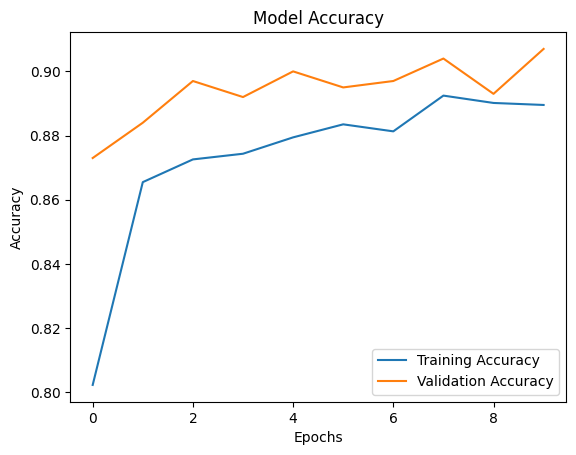

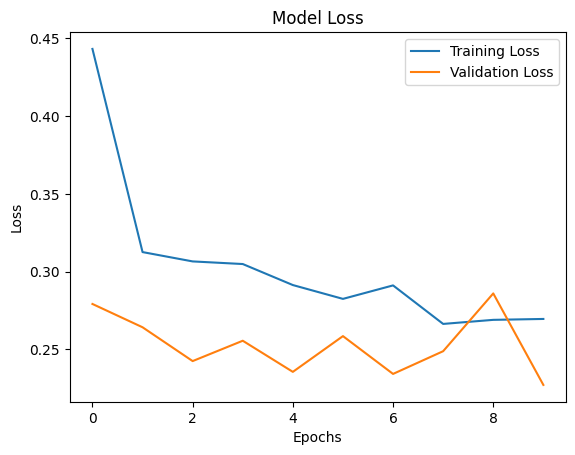

In [ ]:
import matplotlib.pyplot as plt

# Accuracy plot
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss plot
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
# Mount Drive if not mounted
from google.colab import drive
drive.mount('/content/drive')

# Save the accuracy graph
plt.figure()
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('/content/drive/MyDrive/model_accuracy.png')
plt.close()

# Save the loss graph
plt.figure()
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig('/content/drive/MyDrive/model_loss.png')
plt.close()

print("✅ Graphs saved in your Google Drive as model_accuracy.png and model_loss.png")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Graphs saved in your Google Drive as model_accuracy.png and model_loss.png


In [ ]:
import tensorflow as tf, gc
tf.keras.backend.clear_session()
gc.collect()
print("✅ Cleared previous model. Ready for next model.")

✅ Cleared previous model. Ready for next model.


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model2 = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(64,64,3)),
    MaxPooling2D(pool_size=(2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(1, activation='sigmoid')
])

model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
print("✅ Second model created and compiled successfully.")

✅ Second model created and compiled successfully.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

# Path to save checkpoints in Drive
checkpoint_path = "/content/drive/MyDrive/melanoma_checkpoints/model2_best.keras"

# Create callback
checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_accuracy',   # you can also use 'val_loss'
    save_best_only=True,
    mode='max',
    verbose=1
)

print("✅ Checkpoint path ready:", checkpoint_path)

✅ Checkpoint path ready: /content/drive/MyDrive/melanoma_checkpoints/model2_best.keras


In [ ]:
history2 = model2.fit(
    train_set,
    validation_data=test_set,
    epochs=10,
    callbacks=[checkpoint]
)

NameError: name 'train_set' is not defined

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_dir = '/content/melanoma_cancer_dataset/train'
test_dir = '/content/melanoma_cancer_dataset/test'

train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_set = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

test_set = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

FileNotFoundError: [Errno 2] No such file or directory: '/content/melanoma_cancer_dataset/train'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_set = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

test_set = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

FileNotFoundError: [Errno 2] No such file or directory: '/content/melanoma_cancer_dataset/train'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls /content/drive/MyDrive

 1.c
 1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf
 20241207_090732.jpg
 20241207_090737.jpg
 20241207_090740.jpg
 20241207_115024.jpg
 20241207_115038.jpg
 20241210_091021.jpg
'4SN23CS099 (1).jpg'
 4SN23CS099.jpg
 4SN23CS099_Sapna.docx
'Activity_LifeStyle[1] (1).docx'
'Activity_LifeStyle[1].docx'
'AI notes'
'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf'
 archive.zip
 ARM-contrlr-Module-1.pdf
 Classroom
'Colab Notebooks'
'Document from Sapna Shetty (1).pdf'
'Document from Sapna Shetty (2).pdf'
'Document from Sapna Shetty.pdf'
 Extracted_dataset
 Ieee
 InShot_20250325_125240493.jpg
'Mehendi and Pooje'
 melanoma_model.h5
'Milling operation.pdf'
 model_accuracy.png
 model_loss.png
 MyData
 pooje
 Screenshot_20241105-225830_PhonePe.jpg
 Screenshot_20241202-164326_Messages.jpg
'Share Client_security_hash (1).pdf'
'Students Registration.gsheet'
'Untitled form (1).gform'
'Untitled form.gform'
'VTU Result 2024.PDF.pdf'


In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset

melanoma_cancer_dataset


In [ ]:
train_dir = '/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/train'
test_dir = '/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/test'

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_set = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

test_set = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

Found 9605 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [ ]:
history2 = model2.fit(
    train_set,
    validation_data=test_set,
    epochs=10,
    callbacks=[checkpoint]
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


KeyboardInterrupt: 

In [ ]:
from tensorflow.keras.models import load_model
model2 = load_model('/content/drive/MyDrive/melanoma_checkpoints/model2_best.keras')
print("✅ Model reloaded successfully from checkpoint!")

ValueError: File not found: filepath=/content/drive/MyDrive/melanoma_checkpoints/model2_best.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
history2 = model2.fit(
    train_set,
    validation_data=test_set,
    epochs=10,
    callbacks=[checkpoint]
)

Epoch 1/10


ValueError: Exception encountered when calling Sequential.call().

[1mInput 0 of layer "dense" is incompatible with the layer: expected axis -1 of input shape to have value 4608, but received input with shape (None, 86528)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(None, 224, 224, 3), dtype=float32)
  • training=True
  • mask=None
  • kwargs=<class 'inspect._empty'>

In [ ]:
from tensorflow.keras import backend as K
K.clear_session()
print("✅ Old model cleared")

✅ Old model cleared


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

model2 = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
print("✅ New model2 built and compiled successfully!")

✅ New model2 built and compiled successfully!


In [ ]:
history2 = model2.fit(
    train_set,
    validation_data=test_set,
    epochs=10,
    callbacks=[checkpoint]
)

Epoch 1/10
 94/301 ━━━━━━━━━━━━━━━━━━━━ 37:55 11s/step - accuracy: 0.7755 - loss: 9.6344

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!nvidia-smi

Tue Nov  4 16:18:14 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint

In [ ]:
train_dir = "/content/melanoma_cancer_dataset/train"
test_dir = "/content/melanoma_cancer_dataset/test"

In [ ]:
img_size = (128, 128)
batch_size = 16

train_datagen = ImageDataGenerator(rescale=1./255, rotation_range=20, zoom_range=0.2, horizontal_flip=True)
test_datagen = ImageDataGenerator(rescale=1./255)

train_set = train_datagen.flow_from_directory(train_dir, target_size=img_size, batch_size=batch_size, class_mode='binary')
test_set = test_datagen.flow_from_directory(test_dir, target_size=img_size, batch_size=batch_size, class_mode='binary')

FileNotFoundError: [Errno 2] No such file or directory: '/content/melanoma_cancer_dataset/train'

In [ ]:
import os

# List everything inside your content folder
for item in os.listdir("/content"):
    print(item)

.config
drive
sample_data


In [ ]:
import os
os.listdir("/content/drive/MyDrive")

['Colab Notebooks',
 'InShot_20250325_125240493.jpg',
 'Classroom',
 'Milling operation.pdf',
 'VTU Result 2024.PDF.pdf',
 '4SN23CS099 (1).jpg',
 '4SN23CS099.jpg',
 'Document from Sapna Shetty (2).pdf',
 'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf',
 'Share Client_security_hash (1).pdf',
 'Screenshot_20241105-225830_PhonePe.jpg',
 'Screenshot_20241202-164326_Messages.jpg',
 '20241210_091021.jpg',
 '20241207_115038.jpg',
 '20241207_115024.jpg',
 '20241207_090740.jpg',
 '20241207_090737.jpg',
 '20241207_090732.jpg',
 '4SN23CS099_Sapna.docx',
 'Document from Sapna Shetty (1).pdf',
 '1.c',
 'Students Registration.gsheet',
 'ARM-contrlr-Module-1.pdf',
 '1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf',
 'Activity_LifeStyle[1] (1).docx',
 'Activity_LifeStyle[1].docx',
 'AI notes',
 'Untitled form (1).gform',
 'Untitled form.gform',
 'Ieee',
 'Document from Sapna Shetty.pdf',
 'pooje',
 'Mehendi and Pooje',
 'archive.zip',
 'MyData',
 'Extracted_dataset',
 'melanoma_model.h5',
 'mod

In [ ]:
import os
os.listdir("/content/drive/MyDrive/Extracted_dataset")

['melanoma_cancer_dataset']

In [ ]:
os.listdir("/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset")

['test', 'train']

In [ ]:
train_dir = "/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/train"
test_dir = "/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/test"

In [ ]:
img_size = (128, 128)
batch_size = 16

train_datagen = ImageDataGenerator(rescale=1./255, rotation_range=20, zoom_range=0.2, horizontal_flip=True)
test_datagen = ImageDataGenerator(rescale=1./255)

train_set = train_datagen.flow_from_directory(train_dir, target_size=img_size, batch_size=batch_size, class_mode='binary')
test_set = test_datagen.flow_from_directory(test_dir, target_size=img_size, batch_size=batch_size, class_mode='binary')

Found 9605 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(128,128,3))
base_model.trainable = False  # freeze base layers

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
model2 = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
print("✅ MobileNetV2 model built and compiled successfully!")

✅ MobileNetV2 model built and compiled successfully!


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint_path = "/content/drive/MyDrive/melanoma_checkpoints/model2_best.keras"
checkpoint = ModelCheckpoint(
    checkpoint_path,
    save_best_only=True,
    monitor='val_accuracy',
    mode='max'
)
print("✅ Checkpoint path ready:", checkpoint_path)

✅ Checkpoint path ready: /content/drive/MyDrive/melanoma_checkpoints/model2_best.keras


In [ ]:
history2 = model2.fit(
    train_set,
    validation_data=test_set,
    epochs=10,
    callbacks=[checkpoint]
)

NameError: name 'model2' is not defined

In [ ]:
history2 = model2.fit(
    train_set,
    validation_data=test_set,
    epochs=10,
    callbacks=[checkpoint]
)

NameError: name 'model2' is not defined

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ModelCheckpoint
import matplotlib.pyplot as plt
import os

In [ ]:
base_dir = '/content/melanoma_cancer_dataset'
train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'test')

img_size = (224, 224)
batch_size = 32

In [ ]:
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_set = train_datagen.flow_from_directory(
    train_dir, target_size=img_size, batch_size=batch_size, class_mode='binary')

test_set = test_datagen.flow_from_directory(
    test_dir, target_size=img_size, batch_size=batch_size, class_mode='binary')

FileNotFoundError: [Errno 2] No such file or directory: '/content/melanoma_cancer_dataset/train'

In [ ]:
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Actual dataset path
base_dir = '/content/drive/MyDrive/melanoma_cancer_dataset'

# Image parameters
img_size = (224, 224)
batch_size = 32

# Data generators
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2  # 80% for training, 20% for validation
)

train_set = datagen.flow_from_directory(
    base_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    subset='training'
)

test_set = datagen.flow_from_directory(
    base_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    subset='validation'
)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/melanoma_cancer_dataset'

In [ ]:
import os

base_dir = '/content/drive/MyDrive/melanoma_cancer_dataset'
print(os.listdir(base_dir))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/melanoma_cancer_dataset'

In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'InShot_20250325_125240493.jpg', 'Classroom', 'Milling operation.pdf', 'VTU Result 2024.PDF.pdf', '4SN23CS099 (1).jpg', '4SN23CS099.jpg', 'Document from Sapna Shetty (2).pdf', 'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf', 'Share Client_security_hash (1).pdf', 'Screenshot_20241105-225830_PhonePe.jpg', 'Screenshot_20241202-164326_Messages.jpg', '20241210_091021.jpg', '20241207_115038.jpg', '20241207_115024.jpg', '20241207_090740.jpg', '20241207_090737.jpg', '20241207_090732.jpg', '4SN23CS099_Sapna.docx', 'Document from Sapna Shetty (1).pdf', '1.c', 'Students Registration.gsheet', 'ARM-contrlr-Module-1.pdf', '1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf', 'Activity_LifeStyle[1] (1).docx', 'Activity_LifeStyle[1].docx', 'AI notes', 'Untitled form (1).gform', 'Untitled form.gform', 'Ieee', 'Document from Sapna Shetty.pdf', 'pooje', 'Mehendi and Pooje', 'archive.zip', 'MyData', 'Extracted_dataset', 'melanoma_model.h5', 'model_accuracy.png', 'model_loss.png']


In [ ]:
print(os.listdir('/content/drive/MyDrive/Extracted_dataset'))

['melanoma_cancer_dataset']


In [ ]:
train_dir = '/content/drive/MyDrive/Extracted_dataset/train'
test_dir = '/content/drive/MyDrive/Extracted_dataset/test'

In [ ]:
train_set = train_datagen.flow_from_directory(
    train_dir, target_size=img_size, batch_size=batch_size, class_mode='binary')

test_set = test_datagen.flow_from_directory(
    test_dir, target_size=img_size, batch_size=batch_size, class_mode='binary')

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Extracted_dataset/train'

In [ ]:
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Correct base directory
base_dir = '/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset'

# Define train/test directories
train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'test')

# Check contents to be sure
print("Train folders:", os.listdir(train_dir))
print("Test folders:", os.listdir(test_dir))

# Image data setup
img_size = (224, 224)
batch_size = 32

train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_set = train_datagen.flow_from_directory(
    train_dir, target_size=img_size, batch_size=batch_size, class_mode='binary')

test_set = test_datagen.flow_from_directory(
    test_dir, target_size=img_size, batch_size=batch_size, class_mode='binary')

Train folders: ['benign', 'malignant']
Test folders: ['benign', 'malignant']
Found 9605 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [ ]:
history2 = model2.fit(train_set, validation_data=test_set, epochs=3, callbacks=[checkpoint])

NameError: name 'model2' is not defined

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model2 = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(224, 224, 3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
print("✅ model2 recreated and compiled successfully!")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ model2 recreated and compiled successfully!


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint_path = '/content/drive/MyDrive/melanoma_checkpoints/model2_best.keras'
checkpoint = ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True)

history2 = model2.fit(
    train_set,
    validation_data=test_set,
    epochs=3,
    callbacks=[checkpoint]
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/3
301/301 ━━━━━━━━━━━━━━━━━━━━ 3618s 12s/step - accuracy: 0.6842 - loss: 0.5881 - val_accuracy: 0.8670 - val_loss: 0.3087
Epoch 2/3
301/301 ━━━━━━━━━━━━━━━━━━━━ 1096s 4s/step - accuracy: 0.8445 - loss: 0.3562 - val_accuracy: 0.8870 - val_loss: 0.2559
Epoch 3/3
301/301 ━━━━━━━━━━━━━━━━━━━━ 1113s 4s/step - accuracy: 0.8726 - loss: 0.3125 - val_accuracy: 0.8940 - val_loss: 0.2430


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
model2.save('/content/drive/MyDrive/melanoma_model_v1.h5')

In [ ]:
model2.save('/content/drive/MyDrive/melanoma_model_v1.keras')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
os.listdir('/content/drive/MyDrive')


['Colab Notebooks',
 'InShot_20250325_125240493.jpg',
 'Classroom',
 'Milling operation.pdf',
 'VTU Result 2024.PDF.pdf',
 '4SN23CS099 (1).jpg',
 '4SN23CS099.jpg',
 'Document from Sapna Shetty (2).pdf',
 'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf',
 'Share Client_security_hash (1).pdf',
 'Screenshot_20241105-225830_PhonePe.jpg',
 'Screenshot_20241202-164326_Messages.jpg',
 '20241210_091021.jpg',
 '20241207_115038.jpg',
 '20241207_115024.jpg',
 '20241207_090740.jpg',
 '20241207_090737.jpg',
 '20241207_090732.jpg',
 '4SN23CS099_Sapna.docx',
 'Document from Sapna Shetty (1).pdf',
 '1.c',
 'Students Registration.gsheet',
 'ARM-contrlr-Module-1.pdf',
 '1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf',
 'Activity_LifeStyle[1] (1).docx',
 'Activity_LifeStyle[1].docx',
 'AI notes',
 'Untitled form (1).gform',
 'Untitled form.gform',
 'Ieee',
 'Document from Sapna Shetty.pdf',
 'pooje',
 'Mehendi and Pooje',
 'archive.zip',
 'MyData',
 'Extracted_dataset',
 'melanoma_model.h5',
 'mod

In [ ]:
from tensorflow.keras.models import load_model

model2 = load_model('/content/drive/MyDrive/melanoma_model_v1.keras')
print("✅ Model loaded successfully!")


✅ Model loaded successfully!


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
from keras.callbacks import ModelCheckpoint
import os

# Path to your saved model
model_path = "/content/drive/MyDrive/melanoma_model_v1.keras"

# Load the model
from keras.models import load_model
model2 = load_model(model_path)

# Define checkpoint folder
checkpoint_dir = "/content/drive/MyDrive/melanoma_checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

# Save checkpoint after every epoch
checkpoint = ModelCheckpoint(
    filepath=os.path.join(checkpoint_dir, "melanoma_epoch_{epoch:02d}.keras"),
    save_best_only=False,     # Save every epoch, not just best
    save_weights_only=False,
    verbose=1
)

# Continue training from where you left off
# (you can adjust 'initial_epoch' and 'epochs' based on previous runs)
history2 = model2.fit(
    train_set,
    validation_data=test_set,
    initial_epoch=3,   # you already trained 3 epochs before
    epochs=6,          # this will run epochs 4, 5, 6
    callbacks=[checkpoint]
)


NameError: name 'train_set' is not defined

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Path to your dataset
base_dir = '/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset'

train_dir = base_dir + '/train'
test_dir = base_dir + '/test'

# Image size & batch
img_size = (224, 224)
batch_size = 32

# Preprocessing
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# Load train/test sets
train_set = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary'
)

test_set = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary'
)


Found 9605 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [ ]:

from keras.callbacks import ModelCheckpoint, EarlyStopping

# Checkpoint saves after every epoch
checkpoint_callback = ModelCheckpoint(
    filepath="/content/drive/MyDrive/model_checkpoints/model_epoch_{epoch:02d}.h5",
    save_weights_only=False,
    save_freq='epoch',
    verbose=1
)

early_stopping_callback = EarlyStopping(
    monitor='val_accuracy',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Continue training — you already did 3 epochs, so continue till 6
history2 = model2.fit(
    train_set,
    validation_data=test_set,
    epochs=6,           # stop at 6
    initial_epoch=3,    # resume from 3
    callbacks=[checkpoint_callback, early_stopping_callback]
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 4/6
301/301 ━━━━━━━━━━━━━━━━━━━━ 0s 21s/step - accuracy: 0.8714 - loss: 0.3184 
Epoch 4: saving model to /content/drive/MyDrive/model_checkpoints/model_epoch_04.h5


301/301 ━━━━━━━━━━━━━━━━━━━━ 6921s 23s/step - accuracy: 0.8714 - loss: 0.3183 - val_accuracy: 0.8980 - val_loss: 0.2400
Epoch 5/6
301/301 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8753 - loss: 0.2968
Epoch 5: saving model to /content/drive/MyDrive/model_checkpoints/model_epoch_05.h5


301/301 ━━━━━━━━━━━━━━━━━━━━ 1059s 4s/step - accuracy: 0.8753 - loss: 0.2967 - val_accuracy: 0.9020 - val_loss: 0.2821
Epoch 6/6
301/301 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8829 - loss: 0.2822
Epoch 6: saving model to /content/drive/MyDrive/model_checkpoints/model_epoch_06.h5


301/301 ━━━━━━━━━━━━━━━━━━━━ 1040s 3s/step - accuracy: 0.8829 - loss: 0.2822 - val_accuracy: 0.8920 - val_loss: 0.2539
Restoring model weights from the end of the best epoch: 5.


In [ ]:
model2.save("/content/drive/MyDrive/melanoma_model_v2.keras")


In [ ]:
model2.save("/content/drive/MyDrive/melanoma_model_v2.h5")


In [ ]:
import matplotlib.pyplot as plt

# Accuracy
plt.plot(history2.history['accuracy'], label='train acc')
plt.plot(history2.history['val_accuracy'], label='val acc')
plt.legend()
plt.title('Model Accuracy')
plt.savefig('/content/drive/MyDrive/model_accuracy_v2.png')
plt.close()

# Loss
plt.plot(history2.history['loss'], label='train loss')
plt.plot(history2.history['val_loss'], label='val loss')
plt.legend()
plt.title('Model Loss')
plt.savefig('/content/drive/MyDrive/model_loss_v2.png')
plt.close()


In [ ]:
!ls /content/drive/MyDrive


 1.c
 1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf
 20241207_090732.jpg
 20241207_090737.jpg
 20241207_090740.jpg
 20241207_115024.jpg
 20241207_115038.jpg
 20241210_091021.jpg
'4SN23CS099 (1).jpg'
 4SN23CS099.jpg
 4SN23CS099_Sapna.docx
'Activity_LifeStyle[1] (1).docx'
'Activity_LifeStyle[1].docx'
'AI notes'
'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf'
 archive.zip
 ARM-contrlr-Module-1.pdf
 Classroom
'Colab Notebooks'
'Document from Sapna Shetty (1).pdf'
'Document from Sapna Shetty (2).pdf'
'Document from Sapna Shetty.pdf'
 Extracted_dataset
 Ieee
 InShot_20250325_125240493.jpg
'Mehendi and Pooje'
 melanoma_checkpoints
 melanoma_model.h5
 melanoma_model_v1.h5
 melanoma_model_v1.keras
 melanoma_model_v2.h5
 melanoma_model_v2.keras
'Milling operation.pdf'
 model_accuracy.png
 model_accuracy_v2.png
 model_checkpoints
 model_loss.png
 model_loss_v2.png
 MyData
 pooje
 Screenshot_20241105-225830_PhonePe.jpg
 Screenshot_20241202-164326_Messages.jpg
'Share Client_security_hash (

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from keras.models import load_model
model = load_model('/content/drive/MyDrive/melanoma_model_v1.keras')


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
from keras.models import load_model

model = load_model('/content/drive/MyDrive/melanoma_model_v1.keras', compile=False)


In [ ]:
model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])


In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

# Load the image you want to test
img = image.load_img('/content/test_image.jpg', target_size=(224, 224))  # change size based on your model

# Convert to array
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # add batch dimension
img_array = img_array / 255.0  # normalize if trained that way

# Get prediction
prediction = model.predict(img_array)
print(prediction)


FileNotFoundError: [Errno 2] No such file or directory: '/content/test_image.jpg'

In [ ]:
img = image.load_img('/content/drive/MyDrive/melanoma_9606.jpg', target_size=(224, 224))


In [ ]:
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

prediction = model2.predict(img_array)
print(prediction)


NameError: name 'model2' is not defined

In [ ]:
from keras.models import load_model

model2 = load_model('/content/drive/MyDrive/melanoma_model_1.keras')


ValueError: File not found: filepath=/content/drive/MyDrive/melanoma_model_1.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
import os

print(os.listdir("/content/drive/MyDrive"))



['Colab Notebooks', 'InShot_20250325_125240493.jpg', 'Classroom', 'Milling operation.pdf', 'VTU Result 2024.PDF.pdf', '4SN23CS099 (1).jpg', '4SN23CS099.jpg', 'Document from Sapna Shetty (2).pdf', 'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf', 'Share Client_security_hash (1).pdf', 'Screenshot_20241105-225830_PhonePe.jpg', 'Screenshot_20241202-164326_Messages.jpg', '20241210_091021.jpg', '20241207_115038.jpg', '20241207_115024.jpg', '20241207_090740.jpg', '20241207_090737.jpg', '20241207_090732.jpg', '4SN23CS099_Sapna.docx', 'Document from Sapna Shetty (1).pdf', '1.c', 'Students Registration.gsheet', 'ARM-contrlr-Module-1.pdf', '1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf', 'Activity_LifeStyle[1] (1).docx', 'Activity_LifeStyle[1].docx', 'AI notes', 'Untitled form (1).gform', 'Untitled form.gform', 'Ieee', 'Document from Sapna Shetty.pdf', 'pooje', 'Mehendi and Pooje', 'archive.zip', 'MyData', 'Extracted_dataset', 'melanoma_model.h5', 'model_accuracy.png', 'model_loss.png', '

In [ ]:
from keras.models import load_model

model2 = load_model('/content/drive/MyDrive/melanoma_model_v2.keras')
print("✅ Model loaded successfully!")


✅ Model loaded successfully!


In [ ]:
from keras.preprocessing import image
import numpy as np

# Path of your test image
img_path = '/content/drive/MyDrive/melanoma_9606.jpg'

# Load and preprocess
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Predict
prediction = model2.predict(img_array)

# Show result
if prediction[0][0] > 0.5:
    print("🔴 The image is predicted as: MELANOMA (Cancer detected)")
else:
    print("🟢 The image is predicted as: NON-MELANOMA (Healthy skin)")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step
🟢 The image is predicted as: NON-MELANOMA (Healthy skin)


In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

# Load the image (same target size you used for training)
img_path = '/content/drive/MyDrive/melanoma_10105.jpg'
img = image.load_img(img_path, target_size=(224, 224))

# Convert to array and preprocess
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Make prediction
prediction = model2.predict(img_array)

# Interpret result
if prediction[0][0] > 0.5:
    print("🔴 The image is predicted as: MELANOMA (Cancerous skin lesion)")
else:
    print("🟢 The image is predicted as: NON-MELANOMA (Healthy skin)")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
🔴 The image is predicted as: MELANOMA (Cancerous skin lesion)


In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

# Load your image
img_path = '/content/drive/MyDrive/0230MiSmacro-a836f6a3aba34ee3afef3a85de12e913.jpg'
img = image.load_img(img_path, target_size=(224, 224))

# Convert to array and preprocess
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Predict
prediction = model2.predict(img_array)

# Show result
if prediction[0][0] > 0.5:
    print("🔴 The image is predicted as: MELANOMA (Cancerous skin lesion)")
else:
    print("🟢 The image is predicted as: NON-MELANOMA (Healthy skin)")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
🔴 The image is predicted as: MELANOMA (Cancerous skin lesion)


In [ ]:
# app.py
import streamlit as st
from keras.models import load_model
from keras.preprocessing import image
import numpy as np

model = load_model('melanoma_model_v2.keras')

st.title("🌿 Melanoma Skin Cancer Detection")
uploaded_file = st.file_uploader("Upload a skin image", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    img = image.load_img(uploaded_file, target_size=(224, 224))
    img_array = np.expand_dims(image.img_to_array(img) / 255.0, axis=0)
    prediction = model.predict(img_array)[0][0]
    result = "🔴 MELANOMA" if prediction > 0.5 else "🟢 NON-MELANOMA"
    st.image(uploaded_file, caption=result, use_column_width=True)


ModuleNotFoundError: No module named 'streamlit'

In [ ]:
!pip install streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 76.3 MB/s eta 0:00:00


In [ ]:
%%writefile app.py
import streamlit as st
from keras.models import load_model
from keras.preprocessing import image
import numpy as np

# Load your saved model
model = load_model('/content/drive/MyDrive/melanoma_model_v2.keras')

st.title("🩺 Melanoma Skin Cancer Detection")
st.write("Upload an image of skin lesion to check if it's **Melanoma** or **Non-Melanoma**.")

uploaded_file = st.file_uploader("Choose an image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    img = image.load_img(uploaded_file, target_size=(224, 224))
    st.image(img, caption="Uploaded Image", use_column_width=True)

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    prediction = model.predict(img_array)[0][0]
    if prediction > 0.5:
        st.error("⚠️ Predicted as MELANOMA (Cancerous)")
    else:
        st.success("🟢 Predicted as NON-MELANOMA (Healthy)")


Writing app.py


In [ ]:
!streamlit run app.py





  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.119.167.221:8501

  Stopping...


In [ ]:
!pip install pyngrok


In [ ]:
from pyngrok import ngrok

# Start a tunnel on port 8501 (Streamlit’s default)
public_url = ngrok.connect(8501)
print("Public URL:", public_url)


ERROR:pyngrok.process.ngrok:t=2025-11-09T16:29:25+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your authtoken: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2025-11-09T16:29:25+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your authtoken: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your authtoken: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.

In [ ]:
!ngrok config add-authtoken "35FVzm3YtSlbj3CgNoQDysUDs4m_7CDfAWfYihNvi76ZDkR3s"


Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [ ]:
!streamlit run app.py --server.port 8501 &>/dev/null&


In [ ]:
from pyngrok import ngrok
public_url = ngrok.connect(8501)
print("Public URL:", public_url)


Public URL: NgrokTunnel: "https://repealable-estelle-apnoeal.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
from keras.models import load_model
model2 = load_model('/content/drive/MyDrive/melanoma_model_v2.keras')


In [ ]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,        # or however many more you want
    initial_epoch=6   # this tells it to continue from where it stopped
)


NameError: name 'train_generator' is not defined

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    '/content/drive/MyDrive/dataset/train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

val_generator = val_datagen.flow_from_directory(
    '/content/drive/MyDrive/dataset/val',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/dataset/train'

In [ ]:
!ls /content/drive/MyDrive


 0230MiSmacro-a836f6a3aba34ee3afef3a85de12e913.jpg
 1.c
 1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf
 20241207_090732.jpg
 20241207_090737.jpg
 20241207_090740.jpg
 20241207_115024.jpg
 20241207_115038.jpg
 20241210_091021.jpg
'4SN23CS099 (1).jpg'
 4SN23CS099.jpg
 4SN23CS099_Sapna.docx
'Activity_LifeStyle[1] (1).docx'
'Activity_LifeStyle[1].docx'
'AI notes'
'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf'
 archive.zip
 ARM-contrlr-Module-1.pdf
 Classroom
'Colab Notebooks'
'Document from Sapna Shetty (1).pdf'
'Document from Sapna Shetty (2).pdf'
'Document from Sapna Shetty.pdf'
 Extracted_dataset
 Ieee
 InShot_20250325_125240493.jpg
'Mehendi and Pooje'
 melanoma_10105.jpg
 melanoma_10106.jpg
 melanoma_9605.jpg
 melanoma_9606.jpg
 melanoma_9607.jpg
 melanoma_9608.jpg
 melanoma_checkpoints
 melanoma_model.h5
 melanoma_model_v1.h5
 melanoma_model_v1.keras
 melanoma_model_v2.h5
 melanoma_model_v2.keras
'Milling operation.pdf'
 model_accuracy.png
 model_accuracy_v2.png
 model_check

In [ ]:
train_generator = train_datagen.flow_from_directory(
    '/content/drive/MyDrive/Extracted_dataset/train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

val_generator = val_datagen.flow_from_directory(
    '/content/drive/MyDrive/Extracted_dataset/val',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Extracted_dataset/train'

In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset


melanoma_cancer_dataset


In [ ]:
# Continue training — you already did 6 epochs, so continue till 10
history2 = model2.fit(
    train_set,
    validation_data=test_set,
    epochs=10,           # stop at 6
    initial_epoch=7,    # resume from 3
    callbacks=[checkpoint_callback, early_stopping_callback]
)

NameError: name 'train_set' is not defined

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Path to your dataset
base_dir = '/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset'

train_dir = base_dir + '/train'
test_dir = base_dir + '/test'

# Image size & batch
img_size = (224, 224)
batch_size = 32

# Preprocessing
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# Load train/test sets
train_set = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary'
)

test_set = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary'
)

Found 9605 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [ ]:
from keras.callbacks import ModelCheckpoint, EarlyStopping

# Checkpoint saves after every epoch
checkpoint_callback = ModelCheckpoint(
    filepath="/content/drive/MyDrive/model_checkpoints/model_epoch_{epoch:02d}.h5",
    save_weights_only=False,
    save_freq='epoch',
    verbose=1
)

early_stopping_callback = EarlyStopping(
    monitor='val_accuracy',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Continue training — you already did 3 epochs, so continue till 6
history2 = model2.fit(
    train_set,
    validation_data=test_set,
    epochs=10,           # stop at 6
    initial_epoch=7,    # resume from 3
    callbacks=[checkpoint_callback, early_stopping_callback]
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 8/10


In [ ]:
from keras.callbacks import ModelCheckpoint, EarlyStopping

# Checkpoint saves after every epoch
checkpoint_callback = ModelCheckpoint(
    filepath="/content/drive/MyDrive/model_checkpoints/model_epoch_{epoch:02d}.h5",
    save_weights_only=False,
    save_freq='epoch',
    verbose=1
)

early_stopping_callback = EarlyStopping(
    monitor='val_accuracy',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Continue training — you already did 3 epochs, so continue till 6
history2 = model2.fit(
    train_set,
    validation_data=test_set,
    epochs=10,           # stop at 6
    initial_epoch=6,    # resume from 3
    callbacks=[checkpoint_callback, early_stopping_callback]
)

NameError: name 'model2' is not defined

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Path to your dataset
base_dir = '/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset'

train_dir = base_dir + '/train'
test_dir = base_dir + '/test'

# Image size & batch
img_size = (224, 224)
batch_size = 32

# Preprocessing
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# Load train/test sets
train_set = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary'
)

test_set = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary'
)

Found 9605 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [ ]:
from keras.callbacks import ModelCheckpoint, EarlyStopping

# Checkpoint saves after every epoch
checkpoint_callback = ModelCheckpoint(
    filepath="/content/drive/MyDrive/model_checkpoints/model_epoch_{epoch:02d}.h5",
    save_weights_only=False,
    save_freq='epoch',
    verbose=1
)

early_stopping_callback = EarlyStopping(
    monitor='val_accuracy',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Continue training — you already did 3 epochs, so continue till 6
history2 = model2.fit(
    train_set,
    validation_data=test_set,
    epochs=10,           # stop at 6
    initial_epoch=6,    # resume from 3
    callbacks=[checkpoint_callback, early_stopping_callback]
)

NameError: name 'model2' is not defined

In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset


melanoma_cancer_dataset


In [ ]:
import os
os.listdir("/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset")

NameError: name 'os' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from keras.models import load_model
model = load_model('/content/drive/MyDrive/melanoma_model_v2.keras')


In [ ]:
from keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    '/content/drive/MyDrive/Extracted_dataset/train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

val_generator = val_datagen.flow_from_directory(
    '/content/drive/MyDrive/Extracted_dataset/val',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)


ImportError: cannot import name 'ImageDataGenerator' from 'keras.preprocessing.image' (/usr/local/lib/python3.12/dist-packages/keras/preprocessing/image/__init__.py)

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [ ]:
train_generator = train_datagen.flow_from_directory(...)
val_generator = val_datagen.flow_from_directory(...)


NameError: name 'train_datagen' is not defined

In [ ]:
from tensorflow.keras.preprocessing.image import Image


ImportError: cannot import name 'Image' from 'tensorflow.keras.preprocessing.image' (/usr/local/lib/python3.12/dist-packages/keras/_tf_keras/keras/preprocessing/image/__init__.py)

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    '/content/drive/MyDrive/Extracted_dataset/train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

val_generator = val_datagen.flow_from_directory(
    '/content/drive/MyDrive/Extracted_dataset/val',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Extracted_dataset/train'

In [ ]:
!ls /content/drive/MyDrive


 0230MiSmacro-a836f6a3aba34ee3afef3a85de12e913.jpg
 1.c
 1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf
 20241207_090732.jpg
 20241207_090737.jpg
 20241207_090740.jpg
 20241207_115024.jpg
 20241207_115038.jpg
 20241210_091021.jpg
'4SN23CS099 (1).jpg'
 4SN23CS099.jpg
 4SN23CS099_Sapna.docx
'Activity_LifeStyle[1] (1).docx'
'Activity_LifeStyle[1].docx'
'AI notes'
'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf'
 archive.zip
 ARM-contrlr-Module-1.pdf
 Classroom
'Colab Notebooks'
'Document from Sapna Shetty (1).pdf'
'Document from Sapna Shetty (2).pdf'
'Document from Sapna Shetty.pdf'
 Extracted_dataset
 Ieee
 InShot_20250325_125240493.jpg
'Mehendi and Pooje'
 melanoma_10105.jpg
 melanoma_10106.jpg
 melanoma_9605.jpg
 melanoma_9606.jpg
 melanoma_9607.jpg
 melanoma_9608.jpg
 melanoma_checkpoints
 melanoma_model.h5
 melanoma_model_v1.h5
 melanoma_model_v1.keras
 melanoma_model_v2.h5
 melanoma_model_v2.keras
'Milling operation.pdf'
 model_accuracy.png
 model_accuracy_v2.png
 model_check

In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset


melanoma_cancer_dataset


In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset


test  train


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import load_model

# Load your model
model = load_model('/content/drive/MyDrive/melanoma_model_v2.keras')

# Set up data generators
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    '/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

val_generator = val_datagen.flow_from_directory(
    '/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

# Continue training from epoch 6
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,         # train for 4 more epochs (you can change)
    initial_epoch=6    # continue from where you stopped
)

# Save updated model
model.save('/content/drive/MyDrive/melanoma_model_v3.keras')


Found 9605 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 7/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 1023s 3s/step - accuracy: 0.8857 - loss: 0.2739 - val_accuracy: 0.8980 - val_loss: 0.2932
Epoch 8/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 663s 2s/step - accuracy: 0.8868 - loss: 0.2673 - val_accuracy: 0.9100 - val_loss: 0.2468
Epoch 9/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 651s 2s/step - accuracy: 0.8958 - loss: 0.2585 - val_accuracy: 0.8870 - val_loss: 0.2712
Epoch 10/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 641s 2s/step - accuracy: 0.8984 - loss: 0.2499 - val_accuracy: 0.8950 - val_loss: 0.2587


In [ ]:
model.save('/content/drive/MyDrive/final_melanoma_model.h5')


In [ ]:
model.save('/content/drive/MyDrive/best_melanoma_model.keras')


In [ ]:
from tensorflow import keras
model = keras.models.load_model('/content/drive/MyDrive/best_melanoma_model.keras')


In [ ]:
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


NameError: name 'test_generator' is not defined

In [ ]:
/content/drive/MyDrive/melanoma_cancer_dataset/test


NameError: name 'content' is not defined

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    '/content/drive/MyDrive/melanoma_cancer_dataset/test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

# Evaluate model
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/melanoma_cancer_dataset/test'

In [ ]:
/content/drive/MyDrive/Extracted_dataset


NameError: name 'content' is not defined

In [ ]:
/content/drive/MyDrive/Extracted_dataset


NameError: name 'content' is not defined

In [ ]:
content/drive/MyDrive/Extracted_dataset()


NameError: name 'content' is not defined

In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset


melanoma_cancer_dataset


In [ ]:
!ls /content/drive/MyDrive/melanoma_cancer_dataset


ls: cannot access '/content/drive/MyDrive/melanoma_cancer_dataset': No such file or directory


In [ ]:
!ls /content/drive/MyDrive


 0230MiSmacro-a836f6a3aba34ee3afef3a85de12e913.jpg
 1.c
 1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf
 20241207_090732.jpg
 20241207_090737.jpg
 20241207_090740.jpg
 20241207_115024.jpg
 20241207_115038.jpg
 20241210_091021.jpg
'4SN23CS099 (1).jpg'
 4SN23CS099.jpg
 4SN23CS099_Sapna.docx
'Activity_LifeStyle[1] (1).docx'
'Activity_LifeStyle[1].docx'
'AI notes'
'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf'
 archive.zip
 ARM-contrlr-Module-1.pdf
 best_melanoma_model.keras
 Classroom
'Colab Notebooks'
'Document from Sapna Shetty (1).pdf'
'Document from Sapna Shetty (2).pdf'
'Document from Sapna Shetty.pdf'
 Extracted_dataset
 final_melanoma_model.h5
 Ieee
 InShot_20250325_125240493.jpg
'Mehendi and Pooje'
 melanoma_10105.jpg
 melanoma_10106.jpg
 melanoma_9605.jpg
 melanoma_9606.jpg
 melanoma_9607.jpg
 melanoma_9608.jpg
 melanoma_checkpoints
 melanoma_model.h5
 melanoma_model_v1.h5
 melanoma_model_v1.keras
 melanoma_model_v2.h5
 melanoma_model_v2.keras
 melanoma_model_v3.keras
'M

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    '/content/drive/MyDrive/Extracted_dataset/test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Extracted_dataset/test'

In [ ]:
from tensorflow.keras.models import load_model

# Load your best saved model (change name if needed)
model = load_model('/content/drive/MyDrive/best_melanoma_model.keras')

# Evaluate on the test dataset
test_loss, test_acc = model.evaluate(test_generator)
print(f"✅ Test Accuracy: {test_acc*100:.2f}%")
print(f"🧾 Test Loss: {test_loss:.4f}")


NameError: name 'test_generator' is not defined

In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset


melanoma_cancer_dataset


In [ ]:
!ls /content/drive/MyDrive/melanoma_cancer_dataset


ls: cannot access '/content/drive/MyDrive/melanoma_cancer_dataset': No such file or directory


In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset


melanoma_cancer_dataset


In [ ]:
!ls /content/drive/MyDrive


 0230MiSmacro-a836f6a3aba34ee3afef3a85de12e913.jpg
 1.c
 1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf
 20241207_090732.jpg
 20241207_090737.jpg
 20241207_090740.jpg
 20241207_115024.jpg
 20241207_115038.jpg
 20241210_091021.jpg
'4SN23CS099 (1).jpg'
 4SN23CS099.jpg
 4SN23CS099_Sapna.docx
'Activity_LifeStyle[1] (1).docx'
'Activity_LifeStyle[1].docx'
'AI notes'
'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf'
 archive.zip
 ARM-contrlr-Module-1.pdf
 best_melanoma_model.keras
 Classroom
'Colab Notebooks'
'Document from Sapna Shetty (1).pdf'
'Document from Sapna Shetty (2).pdf'
'Document from Sapna Shetty.pdf'
 Extracted_dataset
 final_melanoma_model.h5
 Ieee
 InShot_20250325_125240493.jpg
'Mehendi and Pooje'
 melanoma_10105.jpg
 melanoma_10106.jpg
 melanoma_9605.jpg
 melanoma_9606.jpg
 melanoma_9607.jpg
 melanoma_9608.jpg
 melanoma_checkpoints
 melanoma_model.h5
 melanoma_model_v1.h5
 melanoma_model_v1.keras
 melanoma_model_v2.h5
 melanoma_model_v2.keras
 melanoma_model_v3.keras
'M

In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset


melanoma_cancer_dataset


In [ ]:
!ls /content/drive/MyDrive


 0230MiSmacro-a836f6a3aba34ee3afef3a85de12e913.jpg
 1.c
 1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf
 20241207_090732.jpg
 20241207_090737.jpg
 20241207_090740.jpg
 20241207_115024.jpg
 20241207_115038.jpg
 20241210_091021.jpg
'4SN23CS099 (1).jpg'
 4SN23CS099.jpg
 4SN23CS099_Sapna.docx
'Activity_LifeStyle[1] (1).docx'
'Activity_LifeStyle[1].docx'
'AI notes'
'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf'
 archive.zip
 ARM-contrlr-Module-1.pdf
 best_melanoma_model.keras
 Classroom
'Colab Notebooks'
'Document from Sapna Shetty (1).pdf'
'Document from Sapna Shetty (2).pdf'
'Document from Sapna Shetty.pdf'
 Extracted_dataset
 final_melanoma_model.h5
 Ieee
 InShot_20250325_125240493.jpg
'Mehendi and Pooje'
 melanoma_10105.jpg
 melanoma_10106.jpg
 melanoma_9605.jpg
 melanoma_9606.jpg
 melanoma_9607.jpg
 melanoma_9608.jpg
 melanoma_checkpoints
 melanoma_model.h5
 melanoma_model_v1.h5
 melanoma_model_v1.keras
 melanoma_model_v2.h5
 melanoma_model_v2.keras
 melanoma_model_v3.keras
'M

In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset


melanoma_cancer_dataset


In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset


melanoma_cancer_dataset


In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset


test  train


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    '/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)


Found 1000 images belonging to 2 classes.


In [ ]:
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


32/32 ━━━━━━━━━━━━━━━━━━━━ 22s 683ms/step - accuracy: 0.9058 - loss: 0.2563
Test Accuracy: 89.50%
Test Loss: 0.2587


32/32 ━━━━━━━━━━━━━━━━━━━━ 24s 700ms/step


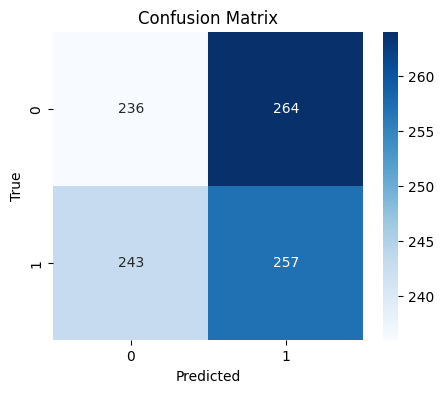

              precision    recall  f1-score   support

      benign       0.49      0.47      0.48       500
   malignant       0.49      0.51      0.50       500

    accuracy                           0.49      1000
   macro avg       0.49      0.49      0.49      1000
weighted avg       0.49      0.49      0.49      1000



In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Predict
Y_pred = model.predict(test_generator)
y_pred = np.round(Y_pred).astype(int).flatten()

# True labels
y_true = test_generator.classes

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Classification Report
print(classification_report(y_true, y_pred, target_names=test_generator.class_indices.keys()))


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATAROOT = '/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset'


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
for p in [DATAROOT, os.path.join(DATAROOT,'train'), os.path.join(DATAROOT,'test')]:
    print("==", p)
    if os.path.exists(p):
        print(os.listdir(p))
    else:
        print("MISSING:", p)

# Count files per class
for split in ['train','test','val','validation']:
    d = os.path.join(DATAROOT, split)
    if os.path.exists(d):
        print("\nSplit:", split)
        for cls in sorted(os.listdir(d)):
            cls_dir = os.path.join(d, cls)
            if os.path.isdir(cls_dir):
                print(cls, ":", len(os.listdir(cls_dir)))


== /content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset
['test', 'train']
== /content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/train
['benign', 'malignant']
== /content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/test
['benign', 'malignant']

Split: train
benign : 5000
malignant : 4605

Split: test
benign : 500
malignant : 500


In [ ]:
import glob, os
train_files = set(glob.glob(os.path.join(DATAROOT,'train','**','*.jpg'), recursive=True))
test_files  = set(glob.glob(os.path.join(DATAROOT,'test','**','*.jpg'), recursive=True))
print("Train images:", len(train_files), "Test images:", len(test_files))
print("Intersection count (should be 0):", len(train_files & test_files))


Train images: 9605 Test images: 1000
Intersection count (should be 0): 0


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = (224,224)
batch_size = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=(0.8,1.2),
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(DATAROOT,'train'),
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary'
)
val_gen = val_datagen.flow_from_directory(
    os.path.join(DATAROOT,'test'),   # or 'val' if you used that split
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    shuffle=False
)


Found 9605 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [ ]:
from sklearn.utils import class_weight
import numpy as np

y = train_gen.classes
classes = np.unique(y)
cw = class_weight.compute_class_weight('balanced', classes=classes, y=y)
class_weights = dict(enumerate(cw))
print("class_weights =", class_weights)


class_weights = {0: np.float64(0.9605), 1: np.float64(1.0428881650380022)}


In [ ]:
import streamlit as st
from keras.models import load_model
from keras.preprocessing import image
import numpy as np
from PIL import Image

# Load your saved model
model = load_model('/content/drive/MyDrive/melanoma_model_v2.keras')

st.title("🩺 Melanoma Skin Cancer Detection")
st.write("Upload an image of a skin lesion to check if it's **Melanoma** or **Non-Melanoma**.")

uploaded_file = st.file_uploader("Choose an image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    img = Image.open(uploaded_file)
    img = img.resize((224, 224))
    st.image(img, caption="Uploaded Image", use_column_width=True)

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    prediction = model.predict(img_array)[0][0]
    if prediction > 0.5:
        st.error("⚠️ Predicted as MELANOMA (Cancerous)")
    else:
        st.success("🟢 Predicted as NON-MELANOMA (Healthy)")


ModuleNotFoundError: No module named 'streamlit'

In [ ]:
!pip install streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 70.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 64.1 MB/s eta 0:00:00


In [ ]:
!pip install streamlit
!pip install pyngrok


In [ ]:
%%writefile app.py
import streamlit as st
from keras.models import load_model
from keras.preprocessing import image
import numpy as np
from PIL import Image

# Load your model
model = load_model('/content/drive/MyDrive/melanoma_model_v2.keras')

st.title("🩺 Melanoma Skin Cancer Detection")
st.write("Upload an image of a skin lesion to check if it's **Melanoma** or **Non-Melanoma**.")

uploaded_file = st.file_uploader("Choose an image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    img = Image.open(uploaded_file)
    img = img.resize((224, 224))
    st.image(img, caption="Uploaded Image", use_column_width=True)

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    prediction = model.predict(img_array)[0][0]
    if prediction > 0.5:
        st.error("⚠️ Predicted as MELANOMA (Cancerous)")
    else:
        st.success("🟢 Predicted as NON-MELANOMA (Healthy)")


Writing app.py


In [ ]:
from pyngrok import ngrok

# Expose the port 8501 for Streamlit
public_url = ngrok.connect(port='8501')
public_url


ERROR:pyngrok.process.ngrok:t=2025-11-10T18:04:50+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your authtoken: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2025-11-10T18:04:50+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your authtoken: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2025-11-10T18:04:50+0000 lvl=eror msg="terminating with error" obj=app err="authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your aut

PyngrokNgrokError: The ngrok process errored on start: authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your authtoken: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.

In [ ]:
from pyngrok import ngrok

# Replace 'YOUR_AUTHTOKEN' with your ngrok token
!ngrok authtoken YOUR_AUTHTOKEN


Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [ ]:
# Start Streamlit in background (no logs shown)
get_ipython().system_raw('streamlit run app.py &')


In [ ]:
from pyngrok import ngrok

# Forward port 8501 (default Streamlit port) to a public URL
public_url = ngrok.connect(port='8501')
public_url


ERROR:pyngrok.process.ngrok:t=2025-11-10T18:07:04+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nYour authtoken: YOUR_AUTHTOKEN\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n"
ERROR:pyngrok.process.ngrok:t=2025-11-10T18:07:04+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nYour authtoken: YOUR_AUTHTOKEN\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nYour authtoken: YOUR_AUTHTOKEN\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n.

In [ ]:
!pip install streamlit pyngrok --quiet


In [ ]:
%%writefile app.py
import streamlit as st
from keras.models import load_model
from keras.preprocessing import image
import numpy as np
from PIL import Image

model = load_model('/content/drive/MyDrive/melanoma_model_v2.keras')

st.title("🩺 Melanoma Skin Cancer Detection")
st.write("Upload an image of a skin lesion to check if it's **Melanoma** or **Non-Melanoma**.")

uploaded_file = st.file_uploader("Choose an image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    img = Image.open(uploaded_file)
    img = img.resize((224, 224))
    st.image(img, caption="Uploaded Image", use_column_width=True)

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    prediction = model.predict(img_array)[0][0]
    if prediction > 0.5:
        st.error("⚠️ Predicted as MELANOMA (Cancerous)")
    else:
        st.success("🟢 Predicted as NON-MELANOMA (Healthy)")


Overwriting app.py


In [ ]:
from pyngrok import ngrok

# Launch Streamlit and expose it to public URL
!streamlit run app.py &>/content/logs.txt &
public_url = ngrok.connect(port='8501')
public_url


ERROR:pyngrok.process.ngrok:t=2025-11-10T18:08:32+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nYour authtoken: YOUR_AUTHTOKEN\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nYour authtoken: YOUR_AUTHTOKEN\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n.

In [ ]:
# 1️⃣ Install dependencies
!pip install streamlit pyngrok --quiet

# 2️⃣ Authenticate ngrok
!ngrok authtoken 35FVzm3YtSlbj3CgNoQDysUDs4m_7CDfAWfYihNvi76ZDkR3s

# 3️⃣ Write your Streamlit app
%%writefile app.py
import streamlit as st
from keras.models import load_model
from keras.preprocessing import image
import numpy as np
from PIL import Image

# Load your model
model = load_model('/content/drive/MyDrive/melanoma_model_v2.keras')

st.title("🩺 Melanoma Skin Cancer Detection")
st.write("Upload an image of a skin lesion to check if it's **Melanoma** or **Non-Melanoma**.")

uploaded_file = st.file_uploader("Choose an image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    img = Image.open(uploaded_file)
    img = img.resize((224, 224))
    st.image(img, caption="Uploaded Image", use_column_width=True)

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    prediction = model.predict(img_array)[0][0]
    if prediction > 0.5:
        st.error("⚠️ Predicted as MELANOMA (Cancerous)")
    else:
        st.success("🟢 Predicted as NON-MELANOMA (Healthy)")

# 4️⃣ Launch Streamlit and expose via ngrok
from pyngrok import ngrok

get_ipython().system_raw('streamlit run app.py &')
public_url = ngrok.connect(port='8501')
public_url


Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


UsageError: Line magic function `%%writefile` not found.


In [ ]:
%%writefile app.py
import streamlit as st
from keras.models import load_model
from keras.preprocessing import image
import numpy as np
from PIL import Image

# Load your model
model = load_model('/content/drive/MyDrive/melanoma_model_v2.keras')

st.title("🩺 Melanoma Skin Cancer Detection")
st.write("Upload an image of a skin lesion to check if it's **Melanoma** or **Non-Melanoma**.")

uploaded_file = st.file_uploader("Choose an image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    img = Image.open(uploaded_file)
    img = img.resize((224, 224))
    st.image(img, caption="Uploaded Image", use_column_width=True)

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    prediction = model.predict(img_array)[0][0]
    if prediction > 0.5:
        st.error("⚠️ Predicted as MELANOMA (Cancerous)")
    else:
        st.success("🟢 Predicted as NON-MELANOMA (Healthy)")


Overwriting app.py


In [ ]:
from pyngrok import ngrok

# Start Streamlit in background
get_ipython().system_raw('streamlit run app.py &')

# Connect ngrok to port 8501
public_url = ngrok.connect(port='8501')
public_url


PyngrokNgrokHTTPError: ngrok client exception, API returned 400: {"error_code":102,"status_code":400,"msg":"invalid tunnel configuration","details":{"err":"yaml: unmarshal errors:\n  line 1: field port not found in type config.HTTPv2Tunnel"}}


In [ ]:
!pkill ngrok


In [ ]:
import os
os.environ["NGROK_CONFIG"] = "/tmp/ngrok.yml"


In [ ]:
# Install dependencies if not installed
!pip install streamlit pyngrok --quiet

# Authenticate ngrok
!ngrok authtoken 35FVzm3YtSlbj3CgNoQDysUDs4m_7CDfAWfYihNvi76ZDkR3s

# Write the app
%%writefile app.py
import streamlit as st
from keras.models import load_model
from keras.preprocessing import image
import numpy as np
from PIL import Image

model = load_model('/content/drive/MyDrive/melanoma_model_v2.keras')

st.title("🩺 Melanoma Skin Cancer Detection")
st.write("Upload an image of a skin lesion to check if it's **Melanoma** or **Non-Melanoma**.")

uploaded_file = st.file_uploader("Choose an image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    img = Image.open(uploaded_file)
    img = img.resize((224, 224))
    st.image(img, caption="Uploaded Image", use_column_width=True)

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    prediction = model.predict(img_array)[0][0]
    if prediction > 0.5:
        st.error("⚠️ Predicted as MELANOMA (Cancerous)")
    else:
        st.success("🟢 Predicted as NON-MELANOMA (Healthy)")

# Start Streamlit in background
get_ipython().system_raw('streamlit run app.py &')

# Connect ngrok to port 8501
from pyngrok import ngrok
public_url = ngrok.connect(8501)
public_url


Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


UsageError: Line magic function `%%writefile` not found.


In [ ]:
app_code = """
import streamlit as st
from keras.models import load_model
from keras.preprocessing import image
import numpy as np
from PIL import Image

model = load_model('/content/drive/MyDrive/melanoma_model_v2.keras')

st.title("🩺 Melanoma Skin Cancer Detection")
st.write("Upload an image of a skin lesion to check if it's **Melanoma** or **Non-Melanoma**.")

uploaded_file = st.file_uploader("Choose an image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    img = Image.open(uploaded_file)
    img = img.resize((224, 224))
    st.image(img, caption="Uploaded Image", use_column_width=True)

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    prediction = model.predict(img_array)[0][0]
    if prediction > 0.5:
        st.error("⚠️ Predicted as MELANOMA (Cancerous)")
    else:
        st.success("🟢 Predicted as NON-MELANOMA (Healthy)")
"""

with open("app.py", "w") as f:
    f.write(app_code)


In [ ]:
from pyngrok import ngrok
import os

# Kill any existing ngrok sessions
!pkill ngrok

# Use a temporary ngrok config to avoid v3 YAML issues
os.environ["NGROK_CONFIG"] = "/tmp/ngrok.yml"

# Start Streamlit in the background
get_ipython().system_raw('streamlit run app.py &')

# Connect ngrok to port 8501
public_url = ngrok.connect(8501)
public_url


<NgrokTunnel: "https://repealable-estelle-apnoeal.ngrok-free.dev" -> "http://localhost:8501">

In [ ]:
pip install gradio tensorflow keras pillow numpy


In [ ]:
import gradio as gr
from keras.models import load_model
from keras.preprocessing import image
import numpy as np
from PIL import Image

# Load your trained model
model = load_model("/path/to/melanoma_model_v2.keras")  # change path if needed

# Prediction function
def predict(img):
    img = img.resize((224, 224))
    img_array = np.expand_dims(np.array(img), axis=0) / 255.0
    pred = model.predict(img_array)[0][0]

    if pred > 0.5:
        return f"⚠️ MELANOMA ({pred*100:.2f}% probability)"
    else:
        return f"🟢 NON-MELANOMA ({(1-pred)*100:.2f}% probability)"

# Gradio interface
iface = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs="text",
    title="🩺 Melanoma Skin Cancer Detection",
    description="Upload an image of a skin lesion to check if it's **Melanoma** or **Non-Melanoma**."
)

# Launch with share=True to get a public URL
iface.launch(share=True)


ValueError: File not found: filepath=/path/to/melanoma_model_v2.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
/content/drive/MyDrive/melanoma_model_v2.keras


NameError: name 'content' is not defined

In [ ]:
from keras.models import load_model

model_path = "/content/drive/MyDrive/melanoma_model_v2.keras"  # put path in quotes
model = load_model(model_path)


In [ ]:
import os
os.path.exists(model_path)  # should return True


True

In [ ]:
# 1️⃣ Install dependencies
!pip install gradio tensorflow keras pillow numpy --quiet

# 2️⃣ Mount Google Drive to access your model
from google.colab import drive
drive.mount('/content/drive')

# 3️⃣ Import libraries
import gradio as gr
from keras.models import load_model
from keras.preprocessing import image
import numpy as np
from PIL import Image

# 4️⃣ Load your model
model_path = "/content/drive/MyDrive/melanoma_model_v2.keras"
model = load_model(model_path)

# 5️⃣ Prediction function
def predict(img):
    img = img.resize((224,224))
    img_array = np.expand_dims(np.array(img), axis=0)/255.0
    pred = model.predict(img_array)[0][0]

    if pred > 0.5:
        return f"⚠️ MELANOMA ({pred*100:.2f}% probability)"
    else:
        return f"🟢 NON-MELANOMA ({(1-pred)*100:.2f}% probability)"

# 6️⃣ Create Gradio interface
iface = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs="text",
    title="🩺 Melanoma Skin Cancer Detection",
    description="Upload a skin lesion image to check if it's **Melanoma** or **Non-Melanoma**."
)

# 7️⃣ Launch Gradio with public link
iface.launch(share=True)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://16160e0fe3418f8b23.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:
import gradio as gr
from keras.models import load_model
import numpy as np
from PIL import Image

model = load_model("/content/drive/MyDrive/melanoma_model_v2.keras")


In [ ]:
def predict(img):
    img = img.resize((224,224))
    img_array = np.expand_dims(np.array(img), axis=0)/255.0
    pred = model.predict(img_array)[0][0]
    return f"MELANOMA ({pred*100:.2f}% probability)" if pred > 0.5 else f"NON-MELANOMA ({(1-pred)*100:.2f}% probability)"

iface = gr.Interface(fn=predict, inputs=gr.Image(type="pil"), outputs="text")
iface.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://64145df564737ef200.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:
import gradio as gr
from keras.models import load_model
import numpy as np
from PIL import Image

model = load_model("/content/drive/MyDrive/melanoma_model_v2.keras")

def predict(img):
    img = img.resize((224,224))
    img_array = np.expand_dims(np.array(img), axis=0)/255.0
    pred = model.predict(img_array)[0][0]
    return f"MELANOMA ({pred*100:.2f}% probability)" if pred > 0.5 else f"NON-MELANOMA ({(1-pred)*100:.2f}% probability)"

iface = gr.Interface(fn=predict, inputs=gr.Image(type="pil"), outputs="text")
iface.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a82683847f06c5880a.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


KeyboardInterrupt: 

In [ ]:
# 1️⃣ Install dependencies (if not already installed)
!pip install gradio tensorflow keras pillow numpy --quiet

# 2️⃣ Mount Google Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# 3️⃣ Import libraries
import gradio as gr
from keras.models import load_model
import numpy as np
from PIL import Image

# 4️⃣ Load your trained model
model_path = "/content/drive/MyDrive/melanoma_model_v2.keras"
model = load_model(model_path)

# 5️⃣ Prediction function
def predict(img):
    img = img.resize((224,224))
    img_array = np.expand_dims(np.array(img), axis=0)/255.0
    pred = model.predict(img_array)[0][0]
    if pred > 0.5:
        return f"⚠️ MELANOMA ({pred*100:.2f}% probability)"
    else:
        return f"🟢 NON-MELANOMA ({(1-pred)*100:.2f}% probability)"

# 6️⃣ Create Gradio interface
iface = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs="text",
    title="🩺 Melanoma Skin Cancer Detection",
    description="Upload a skin lesion image to check if it's **Melanoma** or **Non-Melanoma**."
)

# 7️⃣ Launch Gradio with debug + share
iface.launch(share=True, debug=True, server_name="0.0.0.0", server_port=8080)


Mounted at /content/drive


OSError: Cannot find empty port in range: 8080-8080. You can specify a different port by setting the GRADIO_SERVER_PORT environment variable or passing the `server_port` parameter to `launch()`.

In [ ]:
# 1️⃣ Install dependencies (if not already installed)
!pip install gradio tensorflow keras pillow numpy --quiet

# 2️⃣ Mount Google Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# 3️⃣ Import libraries
import gradio as gr
from keras.models import load_model
import numpy as np
from PIL import Image

# 4️⃣ Load your trained model
model_path = "/content/drive/MyDrive/melanoma_model_v2.keras"
model = load_model(model_path)

# 5️⃣ Prediction function
def predict(img):
    img = img.resize((224,224))
    img_array = np.expand_dims(np.array(img), axis=0)/255.0
    pred = model.predict(img_array)[0][0]
    if pred > 0.5:
        return f"⚠️ MELANOMA ({pred*100:.2f}% probability)"
    else:
        return f"🟢 NON-MELANOMA ({(1-pred)*100:.2f}% probability)"

# 6️⃣ Create Gradio interface
iface = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs="text",
    title="🩺 Melanoma Skin Cancer Detection",
    description="Upload a skin lesion image to check if it's **Melanoma** or **Non-Melanoma**."
)

# 7️⃣ Launch Gradio with safe port
iface.launch(share=True, debug=True, server_name="0.0.0.0", server_port=7860)


Mounted at /content/drive


OSError: Cannot find empty port in range: 7860-7860. You can specify a different port by setting the GRADIO_SERVER_PORT environment variable or passing the `server_port` parameter to `launch()`.

In [ ]:
# 1️⃣ Install dependencies (if not already installed)
!pip install gradio tensorflow keras pillow numpy --quiet

# 2️⃣ Mount Google Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# 3️⃣ Import libraries
import gradio as gr
from keras.models import load_model
import numpy as np
from PIL import Image

# 4️⃣ Load your trained model
model_path = "/content/drive/MyDrive/melanoma_model_v2.keras"  # Change if your path is different
model = load_model(model_path)

# 5️⃣ Prediction function
def predict(img):
    img = img.resize((224,224))
    img_array = np.expand_dims(np.array(img), axis=0)/255.0
    pred = model.predict(img_array)[0][0]
    if pred > 0.5:
        return f"⚠️ MELANOMA ({pred*100:.2f}% probability)"
    else:
        return f"🟢 NON-MELANOMA ({(1-pred)*100:.2f}% probability)"

# 6️⃣ Create Gradio interface
iface = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs="text",
    title="🩺 Melanoma Skin Cancer Detection",
    description="Upload a skin lesion image to check if it's **Melanoma** or **Non-Melanoma**."
)

# 7️⃣ Launch Gradio (auto port, debug mode, Colab widget + public link)
iface.launch(share=True, debug=True, server_name="0.0.0.0")


Mounted at /content/drive
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://22b1c17ca92a6503ff.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step
Keyboard interruption in main thread... closing server.
Killing tunnel 0.0.0.0:7860 <> https://22b1c17ca92a6503ff.gradio.live


In [ ]:
with open("app.py", "w") as f:
    f.write('''\
import gradio as gr
from keras.models import load_model
import numpy as np
from PIL import Image

# Load your trained model (must be in same folder as this file)
model = load_model("melanoma_model_v2.keras")

# Prediction function
def predict(img):
    img = img.resize((224, 224))
    img_array = np.expand_dims(np.array(img), axis=0) / 255.0
    pred = model.predict(img_array)[0][0]
    if pred > 0.5:
        return f"⚠️ MELANOMA ({pred*100:.2f}% probability)"
    else:
        return f"🟢 NON-MELANOMA ({(1-pred)*100:.2f}% probability)"

# Gradio interface
iface = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs="text",
    title="🩺 Melanoma Skin Cancer Detection",
    description="Upload a skin lesion image to check if it's Melanoma or Non-Melanoma."
)

iface.launch()
''')


In [ ]:
from google.colab import drive

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset


melanoma_cancer_dataset


In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset


test  train


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    '/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

test_generator = test_datagen.flow_from_directory(
    '/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False  # Important for confusion matrix
)


Found 9605 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [ ]:
from tensorflow.keras.models import load_model

model = load_model('/content/drive/MyDrive/final_melanoma_model.h5')
# OR (if you want to test another one)
# model = load_model('/content/drive/MyDrive/melanoma_model_v3.keras')


In [ ]:
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


32/32 ━━━━━━━━━━━━━━━━━━━━ 319s 10s/step - accuracy: 0.8693 - loss: 0.3269
Test Accuracy: 89.50%
Test Loss: 0.2587


32/32 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step


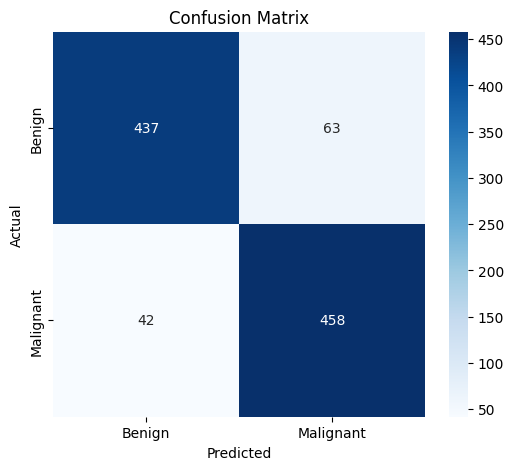

              precision    recall  f1-score   support

      Benign       0.91      0.87      0.89       500
   Malignant       0.88      0.92      0.90       500

    accuracy                           0.90      1000
   macro avg       0.90      0.90      0.89      1000
weighted avg       0.90      0.90      0.89      1000



In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Predict on test set
Y_pred = model.predict(test_generator)
y_pred = np.where(Y_pred > 0.5, 1, 0)

# Get true labels
y_true = test_generator.classes

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print(classification_report(y_true, y_pred, target_names=['Benign', 'Malignant']))


In [ ]:
model.save('/content/drive/MyDrive/final_melanoma_model_v4.h5')


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import numpy as np
import gradio as gr


In [ ]:
model = tf.keras.models.load_model('/content/drive/MyDrive/final_melanoma_model_v4.h5')


In [ ]:
from tensorflow.keras.models import load_model

model = load_model('/content/drive/MyDrive/best_melanoma_model.keras')


In [ ]:
def predict_melanoma(img):
    img = img.resize((224, 224))
    img = np.array(img) / 255.0
    img = np.expand_dims(img, axis=0)

    pred = model.predict(img)[0][0]
    if pred > 0.5:
        return "🩸 Malignant (Cancerous)"
    else:
        return "✅ Benign (Non-Cancerous)"


In [ ]:
interface = gr.Interface(
    fn=predict_melanoma,
    inputs=gr.Image(type="pil"),
    outputs="text",
    title="Melanoma Skin Cancer Detection",
    description="Upload a skin lesion image to detect if it's Benign or Malignant."
)


In [ ]:
interface.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7112ad970aec8065ef.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from tensorflow.keras.models import load_model
model = load_model('/content/drive/MyDrive/final_melanoma_model.h5')


In [ ]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


In [ ]:
def predict_melanoma(img):
    img = img.resize((224, 224))
    img = np.array(img) / 255.0
    img = np.expand_dims(img, axis=0)

    pred = model.predict(img)[0][0]
    if pred > 0.5:
        return "🩸 Malignant (Cancerous)"
    else:
        return "✅ Benign (Non-Cancerous)"


In [ ]:
interface = gr.Interface(
    fn=predict_melanoma,
    inputs=gr.Image(type="pil"),
    outputs="text",
    title="Melanoma Skin Cancer Detection",
    description="Upload a skin lesion image to detect if it's Benign or Malignant."
)


In [ ]:
interface.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://714934640a83617112.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
!pip install -q huggingface_hub gradio
from huggingface_hub import login


In [ ]:
import gradio as gr
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image

# Load your trained model
model = tf.keras.models.load_model("final_melanoma_model.h5")  # or "final_model.keras"

# Class labels
class_names = ["Benign", "Malignant"]

# Prediction function
def predict(img):
    img = img.resize((224, 224))  # same size used during training
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = x / 255.0
    preds = model.predict(x)
    predicted_class = class_names[int(preds[0] > 0.5)]
    confidence = float(preds[0][0]) if predicted_class == "Malignant" else 1 - float(preds[0][0])
    return {predicted_class: round(confidence, 2)}

# Gradio UI
app = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=2),
    title="Melanoma Skin Cancer Detection",
    description="Upload a skin lesion image to classify it as Benign or Malignant using the trained CNN model."
)

app.launch()


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'final_melanoma_model.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
!ls /content/drive/MyDrive/


 0230MiSmacro-a836f6a3aba34ee3afef3a85de12e913.jpg
 1.c
 1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf
 20241207_090732.jpg
 20241207_090737.jpg
 20241207_090740.jpg
 20241207_115024.jpg
 20241207_115038.jpg
 20241210_091021.jpg
'4SN23CS099 (1).jpg'
 4SN23CS099.jpg
 4SN23CS099_Sapna.docx
'Activity_LifeStyle[1] (1).docx'
'Activity_LifeStyle[1].docx'
'AI notes'
'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf'
 archive.zip
 ARM-contrlr-Module-1.pdf
 best_melanoma_model.keras
 Classroom
'Colab Notebooks'
'Document from Sapna Shetty (1).pdf'
'Document from Sapna Shetty (2).pdf'
'Document from Sapna Shetty.pdf'
 Extracted_dataset
 final_melanoma_model.h5
 final_melanoma_model_v4.h5
 Ieee
 InShot_20250325_125240493.jpg
'Mehendi and Pooje'
 melanoma_10105.jpg
 melanoma_10106.jpg
 melanoma_9605.jpg
 melanoma_9606.jpg
 melanoma_9607.jpg
 melanoma_9608.jpg
 melanoma_checkpoints
 melanoma_model.h5
 melanoma_model_v1.h5
 melanoma_model_v1.keras
 melanoma_model_v2.h5
 melanoma_model_v2.keras

In [ ]:
%%writefile app.py
import gradio as gr
import tensorflow as tf
import numpy as np
from PIL import Image

# ✅ Load the trained model
model = tf.keras.models.load_model("/content/drive/MyDrive/final_melanoma_model.h5")

# ✅ Define class labels
class_labels = ['Benign', 'Malignant']

# ✅ Preprocess image
def preprocess_image(image):
    image = image.resize((224, 224))
    image = np.array(image) / 255.0
    image = np.expand_dims(image, axis=0)
    return image

# ✅ Prediction function
def predict(image):
    img = preprocess_image(image)
    prediction = model.predict(img)[0][0]
    label = class_labels[int(prediction > 0.5)]
    confidence = float(prediction if prediction > 0.5 else 1 - prediction)
    return {label: confidence}

# ✅ Gradio interface
interface = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="Upload Skin Lesion Image"),
    outputs=gr.Label(num_top_classes=2),
    title="Melanoma Detection Model",
    description="Upload an image of a skin lesion to predict whether it is **Benign** or **Malignant**."
)

# ✅ Launch app
interface.launch()


Writing app.py


In [ ]:
!ls


app.py	drive  sample_data


In [ ]:
!cp app.py /content/drive/MyDrive/


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
train_dir = "/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/train"
test_dir  = "/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/test"


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
train_dir = "/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/train"
test_dir  = "/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/test"


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)


Found 9605 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/content/drive/MyDrive/final_melanoma_model.h5")


In [ ]:
test_loss, test_acc = model.evaluate(test_gen)
print("Test Accuracy:", test_acc)3
print("Test Loss:", test_loss)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


32/32 ━━━━━━━━━━━━━━━━━━━━ 707s 22s/step - accuracy: 0.8889 - loss: 0.2686
Test Accuracy: 0.8949999809265137
Test Loss: 0.25866836309432983


In [ ]:
from tensorflow.keras.models import load_model
model = load_model("/content/drive/MyDrive/final_melanoma_model.h5")


In [ ]:
import tensorflow as tf

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),   # VERY IMPORTANT
    loss='binary_crossentropy',
    metrics=['accuracy']
)


In [ ]:
history = model.fit(
    train_gen,
    validation_data=test_gen,
    epochs=3
)


Epoch 1/3
301/301 ━━━━━━━━━━━━━━━━━━━━ 2246s 7s/step - accuracy: 0.9043 - loss: 0.2351 - val_accuracy: 0.9090 - val_loss: 0.2298
Epoch 2/3
301/301 ━━━━━━━━━━━━━━━━━━━━ 1123s 4s/step - accuracy: 0.9068 - loss: 0.2181 - val_accuracy: 0.9120 - val_loss: 0.2273
Epoch 3/3
301/301 ━━━━━━━━━━━━━━━━━━━━ 1146s 4s/step - accuracy: 0.9147 - loss: 0.2018 - val_accuracy: 0.9130 - val_loss: 0.2257


In [ ]:
model.save("/content/drive/MyDrive/final_melanoma_model_v6.h5")


In [ ]:
model.save("/content/drive/MyDrive/final_melanoma_model_v6.keras")


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    "/content/drive/MyDrive/Extracted_dataset/test/melanoma_cancer_dataset/test",
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Extracted_dataset/test/melanoma_cancer_dataset/test'

In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset


melanoma_cancer_dataset


In [ ]:
!ls /content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset


test  train


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    "/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/test",
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)


Found 1000 images belonging to 2 classes.


In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model("/content/drive/MyDrive/final_melanoma_model_v6.h5")


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


32/32 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step


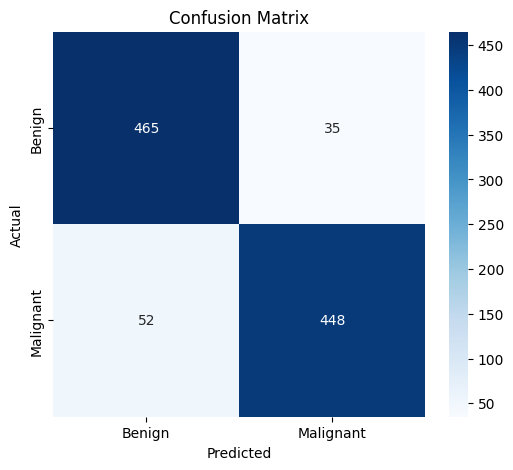

              precision    recall  f1-score   support

      Benign       0.90      0.93      0.91       500
   Malignant       0.93      0.90      0.91       500

    accuracy                           0.91      1000
   macro avg       0.91      0.91      0.91      1000
weighted avg       0.91      0.91      0.91      1000



In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get prediction probabilities
y_prob = model.predict(test_generator)
y_pred = (y_prob > 0.5).astype(int).reshape(-1)

# True labels from generator
y_true = test_generator.classes

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Benign", "Malignant"],
            yticklabels=["Benign", "Malignant"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Classification report
print(classification_report(y_true, y_pred, target_names=["Benign", "Malignant"]))


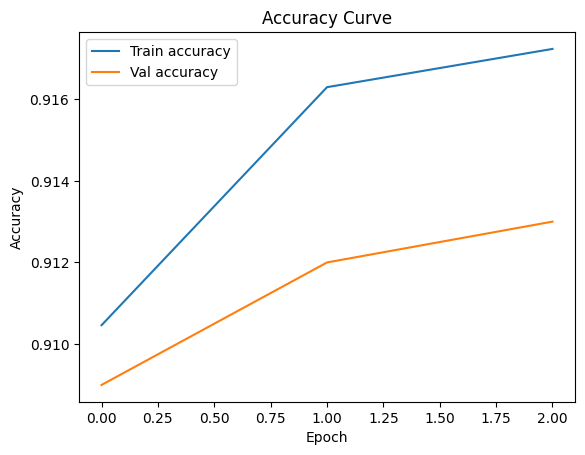

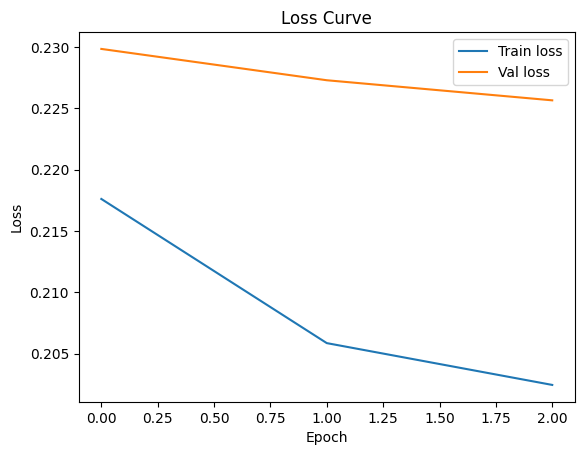

In [ ]:
import matplotlib.pyplot as plt

# Accuracy curve
plt.plot(history.history['accuracy'], label='Train accuracy')
plt.plot(history.history['val_accuracy'], label='Val accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss curve
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Val loss')
plt.title('Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [ ]:
import gradio as gr
from keras.models import load_model
import numpy as np
from PIL import Image, ImageOps

# Load your trained model
model = load_model("final_melanoma_model_v6.h5")   # <-- use your best saved model

# Function: preprocess image exactly like training
def preprocess(img):
    img = img.convert("RGB")                       # ensure RGB
    img = img.resize((224, 224))                   # same size as training
    img_array = np.array(img).astype("float32") / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    return img_array

# Optional: TTA (Test-Time Augmentation) for better accuracy
def tta_predict(img):
    images = []

    # original
    images.append(preprocess(img))

    # flipped
    images.append(preprocess(ImageOps.mirror(img)))

    # rotated slight
    images.append(preprocess(img.rotate(5)))
    images.append(preprocess(img.rotate(-5)))

    preds = []
    for im in images:
        p = model.predict(im)[0][0]
        preds.append(p)

    # average prediction
    final_pred = np.mean(preds)
    return final_pred

# Main prediction function
def predict(img):
    pred = tta_predict(img)
    threshold = 0.60  # medical-safe threshold

    if pred > threshold:
        return f"⚠ MELANOMA ({pred*100:.2f}% confidence)"
    else:
        return f"🟢 NON-MELANOMA ({(1-pred)*100:.2f}% confidence)"

# Gradio Interface
iface = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs="text",
    title="🩺 Melanoma Skin Cancer Detection",
    description="Upload a skin lesion image. The model uses enhanced prediction logic for accuracy."
)

iface.launch()

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'final_melanoma_model_v6.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
!ls


drive  sample_data


In [ ]:
!ls /content/drive/MyDrive


 0230MiSmacro-a836f6a3aba34ee3afef3a85de12e913.jpg
 1.c
 1-d76f0ca6-5675-4f40-8cf1-05c0ccfe9816_copy.pdf
 20241207_090732.jpg
 20241207_090737.jpg
 20241207_090740.jpg
 20241207_115024.jpg
 20241207_115038.jpg
 20241210_091021.jpg
'4SN23CS099 (1).jpg'
 4SN23CS099.jpg
 4SN23CS099_Sapna.docx
'Activity_LifeStyle[1] (1).docx'
'Activity_LifeStyle[1].docx'
'AI notes'
'Applied Chemistry for CSE - simp qb (1) (1)_copy.pdf'
 app.py
 archive.zip
 ARM-contrlr-Module-1.pdf
 best_melanoma_model.keras
 Classroom
'Colab Notebooks'
'Document from Sapna Shetty (1).pdf'
'Document from Sapna Shetty (2).pdf'
'Document from Sapna Shetty (3).pdf'
'Document from Sapna Shetty.pdf'
 _DSC8796.JPG
 _DSC8797.JPG
 _DSC8798.JPG
 _DSC8799.JPG
 _DSC8800.JPG
 _DSC8801.JPG
 _DSC8802.JPG
 _DSC8803.JPG
 _DSC8804.JPG
 _DSC8805.JPG
 _DSC8806.JPG
 _DSC8807.JPG
 _DSC8808.JPG
 _DSC8809.JPG
 _DSC8810.JPG
 _DSC8811.JPG
 _DSC8812.JPG
 _DSC8813.JPG
 _DSC8814.JPG
 _DSC8815.JPG
 _DSC8816.JPG
 _DSC8817.JPG
 _DSC8818.JPG
 _DSC8819.JP

In [ ]:
import gradio as gr
from keras.models import load_model
import numpy as np
from PIL import Image, ImageOps

# Load your trained model
model = load_model("/content/drive/MyDrive/final_melanoma_model_v6.h5")


In [ ]:
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])


In [ ]:
!cp "/content/drive/MyDrive/final_melanoma_model_v6.h5" .


In [ ]:
!ls


drive  final_melanoma_model_v6.h5  sample_data


In [ ]:
import gradio as gr
from keras.models import load_model
import numpy as np
from PIL import Image, ImageOps

# Load your model from local folder
model = load_model("final_melanoma_model_v6.h5")

# Optional: remove warnings
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

# Preprocessing
def preprocess(img):
    img = img.convert("RGB")
    img = img.resize((224, 224))
    arr = np.array(img).astype("float32") / 255.0
    return np.expand_dims(arr, axis=0)

# TTA prediction
def tta_predict(img):
    images = [
        preprocess(img),
        preprocess(ImageOps.mirror(img)),
        preprocess(img.rotate(5)),
        preprocess(img.rotate(-5))
    ]

    preds = [model.predict(x)[0][0] for x in images]
    return np.mean(preds)

# Final prediction
def predict(img):
    pred = tta_predict(img)
    threshold = 0.60

    if pred > threshold:
        return f"⚠️ MELANOMA ({pred*100:.2f}% confidence)"
    else:
        return f"🟢 NON-MELANOMA ({(1-pred)*100:.2f}% confidence)"

gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs="text",
    title="Melanoma Detector – Local Test",
).launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://25318fda1346973324.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from sklearn.metrics import classification_report
import numpy as np

# Get predictions
preds = model.predict(test_gen)
preds = (preds > 0.5).astype("int32").flatten()

print(classification_report(test_gen.classes, preds, target_names=["Benign", "Malignant"]))


NameError: name 'test_gen' is not defined

In [ ]:
import gradio as gr
import tensorflow as tf
import numpy as np
from PIL import Image

# Load your best model
model = tf.keras.models.load_model("final_melanoma_model_v6.h5")

# Class labels
class_names = ["Benign (Non-Melanoma)", "Malignant (Melanoma)"]

# Prediction function
def predict_image(img):
    if img is None:
        return "No image uploaded", None

    # Preprocess
    img = img.resize((224, 224))
    img_array = np.expand_dims(np.array(img), axis=0) / 255.0

    # Prediction
    pred = model.predict(img_array)[0][0]

    if pred > 0.5:
        label = class_names[1]  # Malignant
        probability = pred * 100
        color = "red"
    else:
        label = class_names[0]  # Benign
        probability = (1 - pred) * 100
        color = "green"

    # Stylish HTML output
    result_html = f"""
    <div style='
        padding: 20px;
        border-radius: 12px;
        background: {color};
        color: white;
        font-size: 24px;
        text-align: center;
        font-weight: bold;
    '>
        {label}<br>
        <span style='font-size:18px;'>Probability: {probability:.2f}%</span>
    </div>
    """

    return result_html

# Gradio interface
iface = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="pil", label="Upload Skin Lesion Image"),
    outputs=gr.HTML(label="Prediction Result"),
    title="🩺 Melanoma Skin Cancer Detection",
    description="""
    Upload a dermoscopic image of a skin lesion to detect whether it is **Benign** or **Malignant (Melanoma)**.<br>
    The system uses a Convolutional Neural Network trained on 10,000+ medical skin images.
    """,
    examples=[
        ["melanoma_9606.jpg"],
        ["melanoma_9608.jpg"],
        ["melanoma_10105.jpg"],
        ["melanoma_10106.jpg"]
    ],
    allow_flagging="never",
    theme="soft"
)

iface.launch()


/usr/local/lib/python3.12/dist-packages/gradio/interface.py:415: UserWarning: The `allow_flagging` parameter in `Interface` is deprecated. Use `flagging_mode` instead.
  warnings.warn(


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e219b1e94e0ecf167d.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/content/drive/MyDrive/final_melanoma_model_v6.h5")


In [ ]:
model.save("final_melanoma_model_v6.keras")


In [ ]:
from tensorflow.keras.models import load_model

old_model = load_model("/content/drive/MyDrive/final_melanoma_model_v6.h5")


In [ ]:
config = old_model.get_config()
weights = old_model.get_weights()

from tensorflow.keras.models import Model, Sequential

new_model = Sequential.from_config(config)
new_model.set_weights(weights)


In [ ]:
new_model.save("final_melanoma_model_v6_fixed.keras")


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import matplotlib.pyplot as plt

# Plot Accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

NameError: name 'history' is not defined

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/content/drive/MyDrive/final_melanoma_model_v6.h5")

train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    "/content/drive/MyDrive/Extracted_dataset/train",
    target_size=(224,224),
    batch_size=32,
    class_mode="binary"
)

test_gen = test_datagen.flow_from_directory(
    "/content/drive/MyDrive/Extracted_dataset/test",
    target_size=(224,224),
    batch_size=32,
    class_mode="binary"
)

NameError: name 'ImageDataGenerator' is not defined

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [ ]:
model = load_model("/content/drive/MyDrive/final_melanoma_model_v6.h5")

train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
train_generator = train_datagen.flow_from_directory(
    "/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

test_generator = test_datagen.flow_from_directory(
    "/content/drive/MyDrive/Extracted_dataset/melanoma_cancer_dataset/test",
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

Found 9605 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [ ]:
test_loss, test_acc = model.evaluate(test_generator)
print("Test Accuracy:", test_acc)
print("Test Loss:", test_loss)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


32/32 ━━━━━━━━━━━━━━━━━━━━ 127s 4s/step - accuracy: 0.9026 - loss: 0.2200
Test Accuracy: 0.9129999876022339
Test Loss: 0.2256527543067932


In [2]:
from google.colab import files

files.download('/content/your_notebook.ipynb')


FileNotFoundError: Cannot find file: /content/your_notebook.ipynb

In [3]:
import os

print("Files in /content:")
print(os.listdir('/content'))

Files in /content:
['.config', 'drive', 'sample_data']


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if 'skin' in file.lower() or 'cancer' in file.lower():
            print(os.path.join(root, file))

/content/drive/MyDrive/Colab Notebooks/SkinCaner.ipynb


In [6]:
from google.colab import files

files.download('/content/drive/MyDrive/Colab Notebooks/SkinCaner.ipynb')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import os

base_path = '/content/drive/MyDrive'

for root, dirs, files in os.walk(base_path):
    for file in files:
        if any(word in file.lower() for word in ['skin', 'cancer', 'model']):
            print(os.path.join(root, file))

/content/drive/MyDrive/melanoma_model.h5
/content/drive/MyDrive/model_accuracy.png
/content/drive/MyDrive/model_loss.png
/content/drive/MyDrive/melanoma_model_v1.h5
/content/drive/MyDrive/melanoma_model_v1.keras
/content/drive/MyDrive/melanoma_model_v2.keras
/content/drive/MyDrive/melanoma_model_v2.h5
/content/drive/MyDrive/model_accuracy_v2.png
/content/drive/MyDrive/model_loss_v2.png
/content/drive/MyDrive/melanoma_model_v3.keras
/content/drive/MyDrive/final_melanoma_model.h5
/content/drive/MyDrive/best_melanoma_model.keras
/content/drive/MyDrive/final_melanoma_model_v4.h5
/content/drive/MyDrive/final_melanoma_model_v6.h5
/content/drive/MyDrive/final_melanoma_model_v6.keras
/content/drive/MyDrive/Colab Notebooks/SkinCaner.ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of ML_MiniProject_2_Credit_risk_modelling_Logistic_Regression (1).ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of ML_MiniProject_2_Credit_risk_modelling_Logistic_Regression.ipynb
/content/drive/MyDrive/Classroom

In [8]:
import os
import json

notebook_path = '/content/drive/MyDrive/Colab Notebooks/SkinCaner.ipynb'

with open(notebook_path, 'r', encoding='utf-8') as f:
    notebook = json.load(f)

print("=== MODEL REFERENCES IN NOTEBOOK ===")

for cell in notebook.get('cells', []):
    if cell.get('cell_type') == 'code':
        source = ''.join(cell.get('source', []))
        for line in source.splitlines():
            if any(word in line.lower() for word in
                   ['load_model', '.h5', '.keras', 'model.save']):
                print(line.strip())

print("\n=== MODEL FILE SIZES ===")

base = '/content/drive/MyDrive'

for name in os.listdir(base):
    if name.lower().endswith(('.h5', '.keras')):
        path = os.path.join(base, name)
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{name}: {size_mb:.2f} MB")

=== MODEL REFERENCES IN NOTEBOOK ===
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
model_path = "/content/drive/MyDrive/melanoma_model.h5"
cnn_model.save(model_path)
from tensorflow.keras.models import load_model
model = load_model('/content/drive/MyDrive/melanoma_model.h5')
tf.keras.backend.clear_session()
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint
checkpoint_path = "/content/drive/MyDrive/melanoma_checkpoints/model2_best.keras"
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import load_model
model2 = load_model('/c